# 01 Manual EDA – COMPAS Recidivism Dataset

## 1. Dissertation Alignment

This notebook performs manual exploratory data analysis for the COMPAS recidivism dataset.

It is aligned with the standard research pipeline used for German Credit and Pima Diabetes:

```text
01 Manual EDA
02 Data Preprocessing
03 Baseline Modelling
04 SHAP Interpretation
05 LIME Interpretation
06 SHAP-LIME Disagreement
07 DiCE Counterfactual Recourse
08_01–08_07 EES Framework
```

The goal is to keep the **pipeline structure, saved outputs, result folders, and documentation approach consistent across datasets**, while allowing domain-specific assumptions to differ.

For COMPAS, the domain-specific focus is recidivism prediction, fairness/proxy-risk awareness, leakage prevention, exclusion of COMPAS-generated risk scores, and transparent feature inclusion/exclusion reasoning.

## 2. Objectives of this Notebook

The objectives are to:

- load and compare the available COMPAS raw files;
- select the modelling dataset for the research pipeline;
- inspect dataset structure, missingness, duplicates, and feature types;
- inspect the target variable;
- inspect sensitive and legally/ethically relevant variables such as race, sex, and age;
- identify identifier, leakage, circularity, duplicate, high-cardinality and non-informative variables;
- create a detailed feature dictionary;
- create a formal feature inclusion/exclusion register;
- create a feature audit table for downstream preprocessing and EES documentation;
- save all outputs using the same folder structure used in German Credit and Pima Diabetes.

This notebook does not perform preprocessing or model training. It prepares evidence for Notebook `02_data_preprocessing_compas`.

## 3. Research Assumptions and Modelling Philosophy

The objective of this research pipeline is to predict recidivism outcomes using information available at or before the assessment point, while supporting explainability, fairness awareness, and regulatory transparency.

### Target Assumption

The modelling target is:

```text
is_recid
```

Target interpretation:

```text
0 = no recidivism
1 = recidivism
```

Rows with invalid target values such as `-1` should be excluded during preprocessing.

### Leakage Prevention Assumption

Variables that contain information generated after the prediction point should not be used for modelling. Examples include `r_charge_degree`, `r_charge_desc`, `r_days_from_arrest`, `vr_charge_degree`, `vr_charge_desc`, and `violent_recid`.

These variables are linked to future recidivism or violent-recidivism events and may leak target information.

### Circular Prediction Assumption

COMPAS-generated risk-score outputs should not be used as predictors when the research task is independent recidivism prediction. Examples include `decile_score`, `score_text`, `v_decile_score`, `v_score_text`, and `decile_score.1`.

These are excluded because they represent COMPAS risk assessment outputs, not raw predictors.

### Fairness and Proxy-Risk Assumption

Sensitive variables such as `race`, `sex`, and `age` are retained at this stage for fairness, proxy-risk and explanation auditing.

They are not retained because they are ethically neutral. They are retained so that the model can be transparently assessed for high-stakes fairness concerns.

### Redundancy Assumption

Where two variables encode the same information, the more direct, interpretable variable is preferred. For example, `age` is retained and `age_cat` is excluded because `age_cat` is derived from `age`.

### High-Cardinality Assumption

Very high-cardinality categorical variables may create sparse one-hot features, unstable explanations, and weak generalisability. For example, `c_charge_desc` is excluded because it contains hundreds of categories and is less stable than the simpler `c_charge_degree`.

## 4. Final Feature Decision Philosophy

### Recommended retained modelling features

```text
sex
age
race
juv_fel_count
juv_misd_count
juv_other_count
priors_count
days_b_screening_arrest
c_days_from_compas
c_charge_degree
```

### Recommended excluded features

```text
age_cat
c_charge_desc
r_charge_degree
r_charge_desc
r_days_from_arrest
violent_recid
vr_charge_degree
vr_charge_desc
decile_score
score_text
v_decile_score
v_score_text
decile_score.1
priors_count.1
type_of_assessment
v_type_of_assessment
identifiers
dates
case numbers
```

This feature strategy produces a clean, defensible recidivism prediction dataset while avoiding future-event leakage, circular COMPAS-score prediction, duplicate variables, and high-cardinality instability.

In [1]:
# =========================================================
# 5. Import Required Libraries and Configure Display
# =========================================================

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 250)
pd.set_option("display.max_rows", 250)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# =========================================================
# 6. Mount Google Drive and Configure Standard Paths
# =========================================================

from google.colab import drive
drive.mount('/content/drive')

ROOT_PATH = Path("/content/drive/MyDrive/Master_Research")

DATASET_NAME = "compas"
NOTEBOOK_NAME = "01_manual_eda_compas"

RAW_DATA_PATH = ROOT_PATH / "04_Data" / "01_Raw_Data" / DATASET_NAME

DATA_PATH_RAW = RAW_DATA_PATH / "compas-scores-raw.csv"
DATA_PATH_PARSED = RAW_DATA_PATH / "cox-violent-parsed.csv"
DATA_PATH_FILT = RAW_DATA_PATH / "cox-violent-parsed_filt.csv"

# Selected modelling dataset for this pipeline
DATA_PATH = DATA_PATH_FILT

RESULTS_ROOT = ROOT_PATH / "07_Results" / DATASET_NAME
RESULTS_PATH = RESULTS_ROOT / NOTEBOOK_NAME

DATASETS_PATH = RESULTS_PATH / "datasets"
TABLES_PATH = RESULTS_PATH / "tables"
FIGURES_PATH = RESULTS_PATH / "figures"
LOGS_PATH = RESULTS_PATH / "logs"

for path in [RESULTS_PATH, DATASETS_PATH, TABLES_PATH, FIGURES_PATH, LOGS_PATH]:
    path.mkdir(parents=True, exist_ok=True)

print("Project paths configured.")
print(f"Root path:     {ROOT_PATH}")
print(f"Raw data path: {RAW_DATA_PATH}")
print(f"Results path:  {RESULTS_PATH}")
print(f"Tables path:   {TABLES_PATH}")
print(f"Figures path:  {FIGURES_PATH}")

Mounted at /content/drive
Project paths configured.
Root path:     /content/drive/MyDrive/Master_Research
Raw data path: /content/drive/MyDrive/Master_Research/04_Data/01_Raw_Data/compas
Results path:  /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas
Tables path:   /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables
Figures path:  /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/figures


In [3]:
# =========================================================
# 7. Helper Functions
# =========================================================

def read_csv_safely(path, label, required=True):
    path = Path(path)
    if not path.exists():
        if required:
            raise FileNotFoundError(f"{label} not found at: {path}")
        print(f"Optional file not found: {label} at {path}")
        return pd.DataFrame()
    return pd.read_csv(path)


def save_df(df, filename, folder=None, index=False):
    if folder is None:
        folder = TABLES_PATH
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    output_path = folder / filename
    df.to_csv(output_path, index=index)
    print(f"Saved: {output_path}")
    return output_path


def save_excel(dfs, filename, folder=None):
    if folder is None:
        folder = TABLES_PATH
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    output_path = folder / filename
    with pd.ExcelWriter(output_path, engine="openpyxl") as writer:
        for sheet_name, df_ in dfs.items():
            if isinstance(df_, pd.DataFrame):
                df_.to_excel(writer, sheet_name=sheet_name[:31], index=False)
    print(f"Saved: {output_path}")
    return output_path


def classify_outlier_severity(outlier_pct):
    if pd.isna(outlier_pct):
        return "Not applicable"
    if outlier_pct == 0:
        return "No outliers"
    if outlier_pct <= 1:
        return "Very low"
    if outlier_pct <= 5:
        return "Low"
    if outlier_pct <= 10:
        return "Moderate"
    return "High"


def safe_filename(value):
    return (str(value).replace("/", "_").replace("\\", "_").replace(" ", "_")
            .replace(":", "_").replace("?", "_").replace("*", "_")
            .replace("|", "_").replace("<", "_").replace(">", "_").replace('"', "_"))


def get_feature_status(feature):
    if feature in feature_decision_lookup:
        return feature_decision_lookup[feature]
    return {
        "modelling_decision": "Review",
        "decision_group": "unmapped_feature",
        "reasoning": "Feature not explicitly mapped in the decision register. Review before preprocessing."
    }

## 8. Expanded COMPAS Feature Dictionary

This dictionary defines the working meaning of the COMPAS variables used in this study.

It supports transparent interpretation, preprocessing assumptions and dissertation write-up.

In [4]:
# =========================================================
# 8. Expanded Feature Dictionary
# =========================================================

feature_dictionary = {
    "id": "Internal row or person identifier.",
    "name": "Full name of the individual.",
    "first": "First name of the individual.",
    "last": "Last name of the individual.",
    "sex": "Sex of the individual.",
    "dob": "Date of birth of the individual.",
    "age": "Age in years at the time of COMPAS screening or assessment.",
    "age_cat": "Age category derived from age, typically Less than 25, 25 to 45, or Greater than 45.",
    "race": "Race or ethnicity category recorded in the COMPAS dataset.",
    "juv_fel_count": "Number of juvenile felony offences.",
    "juv_misd_count": "Number of juvenile misdemeanour offences.",
    "juv_other_count": "Number of other juvenile offences.",
    "priors_count": "Total count of prior offences.",
    "priors_count.1": "Duplicate or repeated version of priors_count created during dataset construction or merging.",
    "days_b_screening_arrest": "Number of days between arrest and COMPAS screening.",
    "c_days_from_compas": "Number of days between COMPAS screening and the current charge event.",
    "c_charge_degree": "Degree of the current charge, for example felony or misdemeanour.",
    "c_charge_desc": "Detailed textual description of the current charge.",
    "decile_score": "COMPAS general recidivism decile risk score.",
    "score_text": "COMPAS general recidivism risk category such as Low, Medium or High.",
    "decile_score.1": "Duplicate or alternate COMPAS decile score variable, likely related to violent-risk scoring or merged duplicate score fields.",
    "v_decile_score": "COMPAS violent recidivism decile risk score.",
    "v_score_text": "COMPAS violent recidivism risk category.",
    "is_recid": "General recidivism outcome indicator used as the modelling target.",
    "is_violent_recid": "Violent recidivism outcome indicator.",
    "violent_recid": "Violent recidivism indicator; in this dataset it is 100 percent missing and carries no usable information.",
    "r_charge_degree": "Degree of the recidivism charge, available after a recidivism event.",
    "r_charge_desc": "Description of the recidivism charge, available after a recidivism event.",
    "r_days_from_arrest": "Days from arrest to a recidivism-related event; future/post-outcome information.",
    "vr_charge_degree": "Degree of the violent recidivism charge, available after a violent recidivism event.",
    "vr_charge_desc": "Description of the violent recidivism charge, available after a violent recidivism event.",
    "type_of_assessment": "General COMPAS assessment type. Usually a constant field such as Risk of Recidivism.",
    "v_type_of_assessment": "Violent-recidivism COMPAS assessment type. Usually a constant field such as Risk of Violence.",
    "case_number": "Case identifier.",
    "c_case_number": "Current charge case number.",
    "r_case_number": "Recidivism case number.",
    "vr_case_number": "Violent recidivism case number.",
    "compas_screening_date": "Date of COMPAS screening or assessment.",
    "c_jail_in": "Date of jail admission for the current charge.",
    "c_jail_out": "Date of jail release for the current charge.",
    "c_arrest_date": "Date of arrest for the current charge.",
    "c_offense_date": "Date of offence for the current charge.",
    "r_offense_date": "Date of offence for the recidivism charge.",
    "r_jail_in": "Date of jail admission for recidivism-related charge.",
    "r_jail_out": "Date of jail release for recidivism-related charge.",
    "vr_offense_date": "Date of offence for violent recidivism.",
    "event": "Event flag often used in survival-analysis versions of the dataset.",
    "two_year_recid": "Two-year recidivism outcome indicator, target-adjacent and excluded when is_recid is used as target."
}

feature_dictionary_df = pd.DataFrame([
    {"feature": feature, "feature_description": description}
    for feature, description in feature_dictionary.items()
])

display(feature_dictionary_df)
save_df(feature_dictionary_df, "compas_feature_dictionary.csv")

,feature,feature_description
0,id,Internal row or person identifier.
1,name,Full name of the individual.
2,first,First name of the individual.
3,last,Last name of the individual.
4,sex,Sex of the individual.
5,dob,Date of birth of the individual.
6,age,Age in years at the time of COMPAS screening o...
7,age_cat,"Age category derived from age, typically Less ..."
8,race,Race or ethnicity category recorded in the COM...
9,juv_fel_count,Number of juvenile felony offences.


Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/compas_feature_dictionary.csv


PosixPath('/content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/compas_feature_dictionary.csv')

In [5]:
# =========================================================
# 9. Feature Inclusion and Exclusion Register
# =========================================================

feature_decision_rows = [
    ("sex", "Keep", "sensitive_demographic", "Sensitive demographic variable retained for fairness, explainability and proxy-risk analysis."),
    ("age", "Keep", "sensitive_demographic", "Age in years is retained because it is more informative and less redundant than age categories."),
    ("age_cat", "Remove", "redundant_derived_feature", "Derived directly from age. Removed to reduce redundancy and improve explanation clarity."),
    ("race", "Keep", "sensitive_demographic", "Sensitive demographic variable retained for fairness and proxy-risk evaluation."),
    ("juv_fel_count", "Keep", "criminal_history", "Historical juvenile felony count available before prediction."),
    ("juv_misd_count", "Keep", "criminal_history", "Historical juvenile misdemeanour count available before prediction."),
    ("juv_other_count", "Keep", "criminal_history", "Historical juvenile other-offence count available before prediction."),
    ("priors_count", "Keep", "criminal_history", "Prior-offence count is available at assessment time and is a core recidivism predictor."),
    ("priors_count.1", "Remove", "duplicate_feature", "Likely duplicate of priors_count. Adds no new information and may double-count prior history."),
    ("days_b_screening_arrest", "Keep", "assessment_timing", "Operational timing variable available before or during assessment."),
    ("c_days_from_compas", "Keep", "assessment_timing", "Timing variable related to current charge and COMPAS screening."),
    ("c_charge_degree", "Keep", "current_charge", "Current charge severity is available at prediction time and has legal relevance."),
    ("c_charge_desc", "Remove", "high_cardinality", "Contains many categories, creating sparse one-hot features and unstable explanations. c_charge_degree is retained as simpler charge-severity information."),
    ("r_charge_degree", "Remove", "future_event_leakage", "Recidivism charge degree is known only after a recidivism event and leaks target information."),
    ("r_charge_desc", "Remove", "future_event_leakage", "Recidivism charge description is future information unavailable at prediction time."),
    ("r_days_from_arrest", "Remove", "future_event_leakage", "Post-outcome timing field linked to recidivism event."),
    ("violent_recid", "Remove", "no_information_content", "100 percent missing in the inspected dataset and carries no usable modelling information."),
    ("vr_charge_degree", "Remove", "future_event_leakage", "Violent recidivism charge degree is future-event information."),
    ("vr_charge_desc", "Remove", "future_event_leakage", "Violent recidivism charge description is future-event information."),
    ("type_of_assessment", "Remove", "constant_feature", "Single unique value and therefore no predictive information."),
    ("v_type_of_assessment", "Remove", "constant_feature", "Single unique value and therefore no predictive information."),
    ("decile_score", "Remove", "compas_output_circularity", "COMPAS risk score output. Including it would reproduce COMPAS rather than independently predict recidivism."),
    ("score_text", "Remove", "compas_output_circularity", "COMPAS risk category output derived from risk scoring."),
    ("v_decile_score", "Remove", "compas_output_circularity", "COMPAS violent-risk score output."),
    ("v_score_text", "Remove", "compas_output_circularity", "COMPAS violent-risk category output."),
    ("decile_score.1", "Remove", "compas_output_circularity", "Duplicate or alternate COMPAS score output. Excluded to avoid circularity."),
    ("id", "Remove", "identifier", "Internal identifier with no modelling meaning."),
    ("first", "Remove", "identifier", "Personal identifier."),
    ("last", "Remove", "identifier", "Personal identifier."),
    ("name", "Remove", "identifier", "Personal identifier."),
    ("dob", "Remove", "identifier_or_redundant", "Date of birth is identifying and age is already retained."),
    ("case_number", "Remove", "identifier", "Case identifier."),
    ("c_case_number", "Remove", "identifier", "Current charge case identifier."),
    ("r_case_number", "Remove", "future_event_identifier", "Recidivism case identifier linked to future event."),
    ("vr_case_number", "Remove", "future_event_identifier", "Violent recidivism case identifier linked to future event."),
    ("compas_screening_date", "Remove", "date_or_timing_artifact", "Raw date field excluded for benchmark consistency and portability."),
    ("c_jail_in", "Remove", "date_or_timing_artifact", "Raw jail admission date excluded to reduce timing leakage and date parsing complexity."),
    ("c_jail_out", "Remove", "date_or_timing_artifact", "Raw jail release date excluded to reduce timing leakage and date parsing complexity."),
    ("c_arrest_date", "Remove", "date_or_timing_artifact", "Raw arrest date excluded; engineered timing variable is preferred."),
    ("c_offense_date", "Remove", "date_or_timing_artifact", "Raw offence date excluded for benchmark consistency."),
    ("r_offense_date", "Remove", "future_event_leakage", "Recidivism offence date is future information."),
    ("r_jail_in", "Remove", "future_event_leakage", "Recidivism jail admission date is future information."),
    ("r_jail_out", "Remove", "future_event_leakage", "Recidivism jail release date is future information."),
    ("vr_offense_date", "Remove", "future_event_leakage", "Violent recidivism offence date is future information."),
    ("is_violent_recid", "Remove", "target_adjacent_leakage", "Alternative outcome variable; excluded when is_recid is the modelling target."),
    ("two_year_recid", "Remove", "target_adjacent_leakage", "Alternative recidivism target variable; excluded when is_recid is target."),
    ("event", "Remove", "target_adjacent_or_survival_field", "Event indicator used in survival-analysis formulations; excluded for binary benchmark modelling."),
    ("is_recid", "Target", "target", "Binary target variable for recidivism prediction.")
]

feature_decision_register_df = pd.DataFrame(feature_decision_rows, columns=["feature", "modelling_decision", "decision_group", "reasoning"])
feature_decision_register_df = feature_decision_register_df.merge(feature_dictionary_df, on="feature", how="left")
feature_decision_register_df = feature_decision_register_df[["feature", "feature_description", "modelling_decision", "decision_group", "reasoning"]]
feature_decision_lookup = feature_decision_register_df.set_index("feature")[["modelling_decision", "decision_group", "reasoning"]].to_dict(orient="index")

display(feature_decision_register_df)
save_df(feature_decision_register_df, "feature_inclusion_exclusion_register.csv")

,feature,feature_description,modelling_decision,decision_group,reasoning
0,sex,Sex of the individual.,Keep,sensitive_demographic,Sensitive demographic variable retained for fa...
1,age,Age in years at the time of COMPAS screening o...,Keep,sensitive_demographic,Age in years is retained because it is more in...
2,age_cat,"Age category derived from age, typically Less ...",Remove,redundant_derived_feature,Derived directly from age. Removed to reduce r...
3,race,Race or ethnicity category recorded in the COM...,Keep,sensitive_demographic,Sensitive demographic variable retained for fa...
4,juv_fel_count,Number of juvenile felony offences.,Keep,criminal_history,Historical juvenile felony count available bef...
5,juv_misd_count,Number of juvenile misdemeanour offences.,Keep,criminal_history,Historical juvenile misdemeanour count availab...
6,juv_other_count,Number of other juvenile offences.,Keep,criminal_history,Historical juvenile other-offence count availa...
7,priors_count,Total count of prior offences.,Keep,criminal_history,Prior-offence count is available at assessment...
8,priors_count.1,Duplicate or repeated version of priors_count ...,Remove,duplicate_feature,Likely duplicate of priors_count. Adds no new ...
9,days_b_screening_arrest,Number of days between arrest and COMPAS scree...,Keep,assessment_timing,Operational timing variable available before o...


Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/feature_inclusion_exclusion_register.csv


PosixPath('/content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/feature_inclusion_exclusion_register.csv')

In [6]:
# =========================================================
# 10. Load and Compare Available COMPAS Files
# =========================================================

df_raw = read_csv_safely(DATA_PATH_RAW, "COMPAS raw scores", required=False)
df_parsed = read_csv_safely(DATA_PATH_PARSED, "COMPAS parsed file", required=False)
df_filt = read_csv_safely(DATA_PATH_FILT, "COMPAS filtered parsed file", required=True)

dataset_comparison_df = pd.DataFrame([
    {"dataset_name": "compas-scores-raw.csv", "path": str(DATA_PATH_RAW), "exists": DATA_PATH_RAW.exists(), "n_rows": df_raw.shape[0] if not df_raw.empty else 0, "n_columns": df_raw.shape[1] if not df_raw.empty else 0},
    {"dataset_name": "cox-violent-parsed.csv", "path": str(DATA_PATH_PARSED), "exists": DATA_PATH_PARSED.exists(), "n_rows": df_parsed.shape[0] if not df_parsed.empty else 0, "n_columns": df_parsed.shape[1] if not df_parsed.empty else 0},
    {"dataset_name": "cox-violent-parsed_filt.csv", "path": str(DATA_PATH_FILT), "exists": DATA_PATH_FILT.exists(), "n_rows": df_filt.shape[0], "n_columns": df_filt.shape[1]}
])

display(dataset_comparison_df)
save_df(dataset_comparison_df, "dataset_file_comparison.csv")

df = df_filt.copy()
print("Selected modelling dataset:", DATA_PATH.name)
print("Shape:", df.shape)
display(df.head())

,dataset_name,path,exists,n_rows,n_columns
0,compas-scores-raw.csv,/content/drive/MyDrive/Master_Research/04_Data...,True,60843,28
1,cox-violent-parsed.csv,/content/drive/MyDrive/Master_Research/04_Data...,True,18316,52
2,cox-violent-parsed_filt.csv,/content/drive/MyDrive/Master_Research/04_Data...,True,18316,40


Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/dataset_file_comparison.csv
Selected modelling dataset: cox-violent-parsed_filt.csv
Shape: (18316, 40)


,id,name,first,last,sex,dob,age,age_cat,race,juv_fel_count,decile_score,juv_misd_count,juv_other_count,priors_count,days_b_screening_arrest,c_jail_in,c_jail_out,c_days_from_compas,c_charge_degree,c_charge_desc,is_recid,r_charge_degree,r_days_from_arrest,r_offense_date,r_charge_desc,r_jail_in,violent_recid,is_violent_recid,vr_charge_degree,vr_offense_date,vr_charge_desc,type_of_assessment,decile_score.1,score_text,screening_date,v_type_of_assessment,v_decile_score,v_score_text,priors_count.1,event
0,1.0000,miguel hernandez,miguel,hernandez,Male,18/04/1947,69,Greater than 45,Other,0,1,0,0,0,-1.0000,13/08/2013 6:03,14/08/2013 5:41,1.0000,(F3),Aggravated Assault w/Firearm,0,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,Risk of Recidivism,1,Low,14/08/2013,Risk of Violence,1,Low,0,0
1,2.0000,miguel hernandez,miguel,hernandez,Male,18/04/1947,69,Greater than 45,Other,0,1,0,0,0,-1.0000,13/08/2013 6:03,14/08/2013 5:41,1.0000,(F3),Aggravated Assault w/Firearm,0,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,Risk of Recidivism,1,Low,14/08/2013,Risk of Violence,1,Low,0,0
2,3.0000,michael ryan,michael,ryan,Male,06/02/1985,31,25 - 45,Caucasian,0,5,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,-1,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,Risk of Recidivism,5,Medium,31/12/2014,Risk of Violence,2,Low,0,0
3,4.0000,kevon dixon,kevon,dixon,Male,22/01/1982,34,25 - 45,African-American,0,3,0,0,0,-1.0000,26/01/2013 3:45,05/02/2013 5:36,1.0000,(F3),Felony Battery w/Prior Convict,1,(F3),NaN,05/07/2013,Felony Battery (Dom Strang),NaN,NaN,1,(F3),05/07/2013,Felony Battery (Dom Strang),Risk of Recidivism,3,Low,27/01/2013,Risk of Violence,1,Low,0,1
4,5.0000,ed philo,ed,philo,Male,14/05/1991,24,Less than 25,African-American,0,4,0,1,4,-1.0000,13/04/2013 4:58,14/04/2013 7:02,1.0000,(F3),Possession of Cocaine,1,(M1),0.0000,16/06/2013,Driving Under The Influence,16/06/2013,NaN,0,NaN,NaN,NaN,Risk of Recidivism,4,Low,14/04/2013,Risk of Violence,3,Low,4,0


In [7]:
# =========================================================
# 11. Initial Dataset Overview and Data Quality Checks
# =========================================================

dataset_overview_df = pd.DataFrame([
    {"metric": "n_rows", "value": df.shape[0]},
    {"metric": "n_columns", "value": df.shape[1]},
    {"metric": "duplicate_rows", "value": int(df.duplicated().sum())},
    {"metric": "duplicate_rows_pct", "value": round(float(df.duplicated().mean() * 100), 4)}
])
raw_column_list_df = pd.DataFrame({"column": df.columns.tolist()})

missing_summary_df = pd.DataFrame({"feature": df.columns, "missing_count": df.isna().sum().values, "missing_pct": (df.isna().mean().values * 100).round(4)}).sort_values("missing_pct", ascending=False)
duplicate_summary_df = pd.DataFrame([{"duplicate_rows": int(df.duplicated().sum()), "duplicate_pct": round(float(df.duplicated().mean() * 100), 4)}])
cardinality_summary_df = pd.DataFrame({"feature": df.columns, "n_unique": df.nunique(dropna=False).values, "unique_pct": (df.nunique(dropna=False).values / len(df) * 100).round(4)}).sort_values("n_unique", ascending=False)

for obj, name in [(dataset_overview_df,"dataset_overview.csv"),(raw_column_list_df,"raw_column_list.csv"),(missing_summary_df,"missing_values_summary.csv"),(duplicate_summary_df,"duplicate_summary.csv"),(cardinality_summary_df,"cardinality_summary.csv")]:
    display(obj.head(40) if len(obj)>40 else obj)
    save_df(obj, name)

,metric,value
0,n_rows,18316.0000
1,n_columns,40.0000
2,duplicate_rows,2803.0000
3,duplicate_rows_pct,15.3036


Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/dataset_overview.csv


,column
0,id
1,name
2,first
3,last
4,sex
5,dob
6,age
7,age_cat
8,race
9,juv_fel_count


Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/raw_column_list.csv


,feature,missing_count,missing_pct
26,violent_recid,18316,100.0000
29,vr_offense_date,16977,92.6895
28,vr_charge_degree,16977,92.6895
30,vr_charge_desc,16977,92.6895
25,r_jail_in,11957,65.2817
22,r_days_from_arrest,11957,65.2817
24,r_charge_desc,10039,54.8100
21,r_charge_degree,9899,54.0456
23,r_offense_date,9899,54.0456
0,id,7315,39.9378


Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/missing_values_summary.csv


,duplicate_rows,duplicate_pct
0,2803,15.3036


Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/duplicate_summary.csv


,feature,n_unique,unique_pct
0,id,11002,60.0677
1,name,10855,59.2651
15,c_jail_in,9807,53.5434
16,c_jail_out,8715,47.5813
5,dob,7485,40.8659
3,last,5635,30.7655
2,first,3876,21.1618
23,r_offense_date,1076,5.8746
25,r_jail_in,973,5.3123
34,screening_date,703,3.8382


Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/cardinality_summary.csv


,target_value,count,pct,interpretation
0,0,9079,49.5687,No recidivism
1,1,8417,45.9544,Recidivism
2,-1,820,4.4770,Invalid or unclear target value requiring prep...


Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/target_distribution.csv


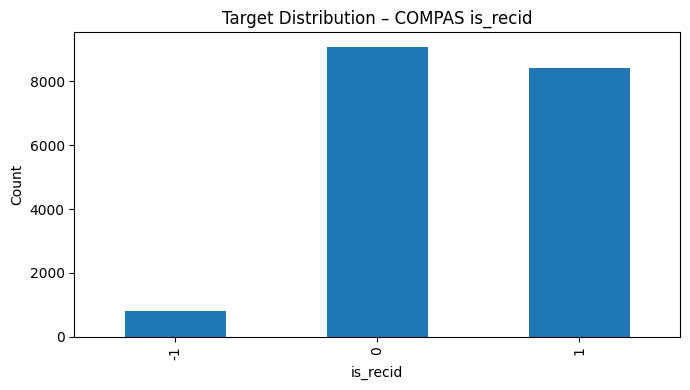

In [8]:
# =========================================================
# 12. Target Variable Inspection
# =========================================================

TARGET = "is_recid"
if TARGET not in df.columns:
    raise ValueError(f"Target column '{TARGET}' not found. Available columns: {df.columns.tolist()}")

target_distribution_df = df[TARGET].value_counts(dropna=False).rename_axis("target_value").reset_index(name="count")
target_distribution_df["pct"] = (target_distribution_df["count"] / len(df) * 100).round(4)
target_interpretation = {0: "No recidivism", 1: "Recidivism", -1: "Invalid or unclear target value requiring preprocessing exclusion"}
target_distribution_df["interpretation"] = target_distribution_df["target_value"].map(target_interpretation).fillna("Other or unexpected value")

display(target_distribution_df)
save_df(target_distribution_df, "target_distribution.csv")

plt.figure(figsize=(7, 4))
df[TARGET].value_counts(dropna=False).sort_index().plot(kind="bar")
plt.title("Target Distribution – COMPAS is_recid")
plt.xlabel("is_recid")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "target_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

In [9]:
# =========================================================
# 13. Feature Types and Summary Statistics
# =========================================================

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

column_type_summary_df = pd.DataFrame({"feature": df.columns, "dtype": [str(dtype) for dtype in df.dtypes], "feature_type": ["numeric" if col in numeric_cols else "categorical" for col in df.columns]})
numeric_summary_df = df[numeric_cols].describe().T.reset_index().rename(columns={"index": "feature"}) if numeric_cols else pd.DataFrame()
if not numeric_summary_df.empty:
    numeric_summary_df["missing_pct"] = numeric_summary_df["feature"].map(dict(zip(missing_summary_df["feature"], missing_summary_df["missing_pct"])))

categorical_summary_rows = []
for col in categorical_cols:
    vc = df[col].value_counts(dropna=False)
    top_value = vc.index[0] if len(vc) > 0 else np.nan
    top_count = vc.iloc[0] if len(vc) > 0 else 0
    categorical_summary_rows.append({"feature": col, "n_unique": df[col].nunique(dropna=False), "top_value": str(top_value), "top_value_count": int(top_count), "top_value_pct": round(float(top_count / len(df) * 100), 4), "missing_pct": round(float(df[col].isna().mean() * 100), 4), "high_cardinality_flag": df[col].nunique(dropna=False) > 10})
categorical_summary_df = pd.DataFrame(categorical_summary_rows)

for obj,name in [(column_type_summary_df,"column_type_summary.csv"),(numeric_summary_df,"numeric_summary_statistics.csv"),(categorical_summary_df,"categorical_summary_statistics.csv")]:
    display(obj)
    save_df(obj,name)

for col in categorical_cols:
    cat_df = df[col].value_counts(dropna=False).rename_axis(col).reset_index(name="count")
    cat_df["pct"] = (cat_df["count"] / len(df) * 100).round(4)
    save_df(cat_df, f"categorical_distribution_{safe_filename(col)}.csv")

,feature,dtype,feature_type
0,id,float64,numeric
1,name,object,categorical
2,first,object,categorical
3,last,object,categorical
4,sex,object,categorical
5,dob,object,categorical
6,age,int64,numeric
7,age_cat,object,categorical
8,race,object,categorical
9,juv_fel_count,int64,numeric


Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/column_type_summary.csv


,feature,count,mean,std,min,25%,50%,75%,max,missing_pct
0,id,11001.0000,5501.0000,3175.8595,1.0000,2751.0000,5501.0000,8251.0000,11001.0000,39.9378
1,age,18316.0000,34.0193,11.6678,18.0000,25.0000,31.0000,41.0000,96.0000,0.0000
2,juv_fel_count,18316.0000,0.0769,0.4643,0.0000,0.0000,0.0000,0.0000,20.0000,0.0000
3,decile_score,18316.0000,4.9971,2.9376,-1.0000,2.0000,5.0000,8.0000,10.0000,0.0000
4,juv_misd_count,18316.0000,0.0984,0.5176,0.0000,0.0000,0.0000,0.0000,13.0000,0.0000
5,juv_other_count,18316.0000,0.1243,0.5245,0.0000,0.0000,0.0000,0.0000,17.0000,0.0000
6,priors_count,18316.0000,3.9132,5.2999,0.0000,0.0000,2.0000,5.0000,43.0000,0.0000
7,days_b_screening_arrest,17019.0000,4.3025,81.1599,-597.0000,-1.0000,-1.0000,0.0000,1057.0000,7.0812
8,c_days_from_compas,17449.0000,57.6946,317.9947,0.0000,1.0000,1.0000,2.0000,9485.0000,4.7336
9,is_recid,18316.0000,0.4148,0.5764,-1.0000,0.0000,0.0000,1.0000,1.0000,0.0000


Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/numeric_summary_statistics.csv


,feature,n_unique,top_value,top_value_count,top_value_pct,missing_pct,high_cardinality_flag
0,name,10855,valerie agostino,13,0.0710,0.0000,True
1,first,3876,michael,421,2.2985,0.0000,True
2,last,5635,williams,239,1.3049,0.0000,True
3,sex,2,Male,14933,81.5298,0.0000,False
4,dob,7485,21/11/1991,21,0.1147,0.0000,True
5,age_cat,3,25 - 45,10372,56.6281,0.0000,False
6,race,6,African-American,9791,53.4560,0.0000,False
7,c_jail_in,9807,nan,1297,7.0812,7.0812,True
8,c_jail_out,8715,nan,1297,7.0812,7.0812,True
9,c_charge_degree,15,(F3),10294,56.2022,4.7336,True


Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/categorical_summary_statistics.csv
Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/categorical_distribution_name.csv
Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/categorical_distribution_first.csv
Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/categorical_distribution_last.csv
Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/categorical_distribution_sex.csv
Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/categorical_distribution_dob.csv
Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/categorical_distribution_age_cat.csv
Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/categorical_distributio

In [10]:
# =========================================================
# 14. Outlier and Correlation Audit
# =========================================================

outlier_rows = []
for col in numeric_cols:
    series = df[col].dropna()
    if series.empty:
        outlier_rows.append({"feature": col, "q1": np.nan, "q3": np.nan, "iqr": np.nan, "lower_bound": np.nan, "upper_bound": np.nan, "outlier_count": 0, "outlier_pct": np.nan, "outlier_severity": "Not applicable"})
        continue
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lb, ub = q1 - 1.5*iqr, q3 + 1.5*iqr
    cnt = int(((series < lb) | (series > ub)).sum())
    pct = round(float(cnt / len(series) * 100), 4)
    outlier_rows.append({"feature": col, "q1": q1, "q3": q3, "iqr": iqr, "lower_bound": lb, "upper_bound": ub, "outlier_count": cnt, "outlier_pct": pct, "outlier_severity": classify_outlier_severity(pct)})
outlier_summary_df = pd.DataFrame(outlier_rows).sort_values("outlier_pct", ascending=False, na_position="last")
display(outlier_summary_df.head(40))
save_df(outlier_summary_df, "outlier_summary.csv")

if len(numeric_cols) >= 2:
    correlation_matrix_df = df[numeric_cols].corr()
    high_corr_rows=[]
    for i in range(len(correlation_matrix_df.columns)):
        for j in range(i+1,len(correlation_matrix_df.columns)):
            corr=correlation_matrix_df.iloc[i,j]
            if abs(corr)>=0.80:
                high_corr_rows.append({"feature_1":correlation_matrix_df.columns[i],"feature_2":correlation_matrix_df.columns[j],"correlation":corr,"abs_correlation":abs(corr)})
    high_correlation_pairs_df=pd.DataFrame(high_corr_rows).sort_values("abs_correlation", ascending=False) if high_corr_rows else pd.DataFrame(columns=["feature_1","feature_2","correlation","abs_correlation"])
    correlation_matrix_df.to_csv(TABLES_PATH / "correlation_matrix.csv")
else:
    correlation_matrix_df=pd.DataFrame(); high_correlation_pairs_df=pd.DataFrame()
display(high_correlation_pairs_df)
save_df(high_correlation_pairs_df, "high_correlation_pairs.csv")

,feature,q1,q3,iqr,lower_bound,upper_bound,outlier_count,outlier_pct,outlier_severity
8,c_days_from_compas,1.0000,2.0000,1.0000,-0.5000,3.5000,3995,22.8953,High
7,days_b_screening_arrest,-1.0000,0.0000,1.0000,-2.5000,1.5000,3862,22.6923,High
10,r_days_from_arrest,0.0000,1.0000,1.0000,-1.5000,2.5000,955,15.0181,High
5,juv_other_count,0.0000,0.0000,0.0000,0.0000,0.0000,1512,8.2551,Moderate
6,priors_count,0.0000,5.0000,5.0000,-7.5000,12.5000,1430,7.8074,Moderate
15,priors_count.1,0.0000,5.0000,5.0000,-7.5000,12.5000,1430,7.8074,Moderate
12,is_violent_recid,0.0000,0.0000,0.0000,0.0000,0.0000,1339,7.3105,Moderate
4,juv_misd_count,0.0000,0.0000,0.0000,0.0000,0.0000,1110,6.0603,Moderate
2,juv_fel_count,0.0000,0.0000,0.0000,0.0000,0.0000,850,4.6408,Low
16,event,0.0000,0.0000,0.0000,0.0000,0.0000,819,4.4715,Low


Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/outlier_summary.csv


,feature_1,feature_2,correlation,abs_correlation
0,decile_score,decile_score.1,1.0000,1.0000
1,priors_count,priors_count.1,1.0000,1.0000


Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/high_correlation_pairs.csv


PosixPath('/content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/high_correlation_pairs.csv')

In [11]:
# =========================================================
# 15. Target Relationships
# =========================================================

numeric_target_summary_rows=[]
for col in numeric_cols:
    if col == TARGET: continue
    temp=df.groupby(TARGET)[col].agg(["count","mean","median","std","min","max"]).reset_index()
    temp["feature"]=col
    numeric_target_summary_rows.append(temp)
numeric_by_target_df=pd.concat(numeric_target_summary_rows, ignore_index=True) if numeric_target_summary_rows else pd.DataFrame()
display(numeric_by_target_df.head(80))
save_df(numeric_by_target_df, "numeric_features_by_target_summary.csv")

categorical_target_rows=[]
for col in categorical_cols:
    if col == TARGET: continue
    ct=pd.crosstab(df[col], df[TARGET], normalize="index", dropna=False)*100
    ct=ct.reset_index()
    for _, row in ct.iterrows():
        out={"feature":col,"category":row[col]}
        for tv in [c for c in ct.columns if c != col]: out[f"target_{tv}_pct"]=row[tv]
        categorical_target_rows.append(out)
categorical_by_target_df=pd.DataFrame(categorical_target_rows)
display(categorical_by_target_df.head(80))
save_df(categorical_by_target_df, "categorical_features_by_target_summary.csv")

,is_recid,count,mean,median,std,min,max,feature
0,-1,459,5513.9063,5458.0000,3104.9603,3.0000,10966.0000,id
1,0,5549,5450.9076,5388.0000,3151.3674,1.0000,10998.0000,id
2,1,4993,5555.4841,5595.0000,3208.9614,4.0000,11001.0000,id
3,-1,820,35.4878,32.0000,12.9036,18.0000,78.0000,age
4,0,9079,35.7886,33.0000,12.1864,18.0000,83.0000,age
5,1,8417,31.9677,29.0000,10.5865,18.0000,96.0000,age
6,-1,820,0.0000,0.0000,0.0000,0.0000,0.0000,juv_fel_count
7,0,9079,0.0464,0.0000,0.3364,0.0000,13.0000,juv_fel_count
8,1,8417,0.1173,0.0000,0.5863,0.0000,20.0000,juv_fel_count
9,-1,820,4.1634,4.0000,2.9060,-1.0000,10.0000,decile_score


Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/numeric_features_by_target_summary.csv


,feature,category,target_-1_pct,target_0_pct,target_1_pct
0,name,aajah herrington,0.0000,0.0000,100.0000
1,name,aaliyah lovo,0.0000,100.0000,0.0000
2,name,aaron aprile,0.0000,100.0000,0.0000
3,name,aaron davis,0.0000,0.0000,100.0000
4,name,aaron eddins,0.0000,0.0000,100.0000
5,name,aaron epstein,0.0000,0.0000,100.0000
6,name,aaron evans,0.0000,0.0000,100.0000
7,name,aaron gilliam,0.0000,100.0000,0.0000
8,name,aaron gunn,0.0000,100.0000,0.0000
9,name,aaron hammond,0.0000,0.0000,100.0000


Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/categorical_features_by_target_summary.csv


PosixPath('/content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/categorical_features_by_target_summary.csv')

In [12]:
# =========================================================
# 16. Sensitive, Proxy-Risk and Feature Audit Tables
# =========================================================

sensitive_features = ["race", "sex", "age"]
demographic_redundant_features = ["age_cat"]
criminal_history_features = ["priors_count", "juv_fel_count", "juv_misd_count", "juv_other_count"]
current_charge_features = ["c_charge_degree", "c_charge_desc"]
assessment_timing_features = ["days_b_screening_arrest", "c_days_from_compas"]
future_event_features = ["r_charge_degree", "r_charge_desc", "r_days_from_arrest", "violent_recid", "vr_charge_degree", "vr_charge_desc", "r_offense_date", "r_jail_in", "r_jail_out", "vr_offense_date"]
compas_output_features = ["decile_score", "score_text", "v_decile_score", "v_score_text", "decile_score.1"]
identifier_features = ["id", "name", "first", "last", "dob", "case_number", "c_case_number", "r_case_number", "vr_case_number"]
constant_or_noninformative_features = ["type_of_assessment", "v_type_of_assessment"]
duplicate_features = ["priors_count.1"]
available_sensitive_features = [col for col in sensitive_features if col in df.columns]

sensitive_proxy_audit_rows=[]
for col in df.columns:
    status=get_feature_status(col)
    sensitive_proxy_audit_rows.append({"feature":col,"feature_description":feature_dictionary.get(col,"No manual description provided."),"sensitive_or_demographic":col in sensitive_features or col in demographic_redundant_features,"legally_relevant":col in criminal_history_features or col in current_charge_features,"future_event_leakage":col in future_event_features,"compas_output_circularity":col in compas_output_features,"identifier":col in identifier_features,"duplicate_risk":col in duplicate_features,"constant_or_noninformative":col in constant_or_noninformative_features,"modelling_decision":status["modelling_decision"],"decision_group":status["decision_group"],"reasoning":status["reasoning"]})
sensitive_proxy_audit_df=pd.DataFrame(sensitive_proxy_audit_rows)
display(sensitive_proxy_audit_df)
save_df(sensitive_proxy_audit_df, "sensitive_proxy_risk_audit.csv")

sens_dist=[]; sens_rates=[]
for col in available_sensitive_features:
    vc=df[col].value_counts(dropna=False)
    for value,count in vc.items(): sens_dist.append({"feature":col,"value":value,"count":int(count),"pct":round(float(count/len(df)*100),4)})
    rates=pd.crosstab(df[col], df[TARGET], normalize="index", dropna=False)*100
    rates=rates.reset_index()
    for _, row in rates.iterrows():
        out={"feature":col,"value":row[col]}
        for tv in [c for c in rates.columns if c != col]: out[f"target_{tv}_pct"]=row[tv]
        sens_rates.append(out)
sensitive_distribution_df=pd.DataFrame(sens_dist); sensitive_target_rates_df=pd.DataFrame(sens_rates)
save_df(sensitive_distribution_df,"sensitive_variable_distributions.csv"); save_df(sensitive_target_rates_df,"sensitive_variable_target_rates.csv")

,feature,feature_description,sensitive_or_demographic,legally_relevant,future_event_leakage,compas_output_circularity,identifier,duplicate_risk,constant_or_noninformative,modelling_decision,decision_group,reasoning
0,id,Internal row or person identifier.,False,False,False,False,True,False,False,Remove,identifier,Internal identifier with no modelling meaning.
1,name,Full name of the individual.,False,False,False,False,True,False,False,Remove,identifier,Personal identifier.
2,first,First name of the individual.,False,False,False,False,True,False,False,Remove,identifier,Personal identifier.
3,last,Last name of the individual.,False,False,False,False,True,False,False,Remove,identifier,Personal identifier.
4,sex,Sex of the individual.,True,False,False,False,False,False,False,Keep,sensitive_demographic,Sensitive demographic variable retained for fa...
5,dob,Date of birth of the individual.,False,False,False,False,True,False,False,Remove,identifier_or_redundant,Date of birth is identifying and age is alread...
6,age,Age in years at the time of COMPAS screening o...,True,False,False,False,False,False,False,Keep,sensitive_demographic,Age in years is retained because it is more in...
7,age_cat,"Age category derived from age, typically Less ...",True,False,False,False,False,False,False,Remove,redundant_derived_feature,Derived directly from age. Removed to reduce r...
8,race,Race or ethnicity category recorded in the COM...,True,False,False,False,False,False,False,Keep,sensitive_demographic,Sensitive demographic variable retained for fa...
9,juv_fel_count,Number of juvenile felony offences.,False,True,False,False,False,False,False,Keep,criminal_history,Historical juvenile felony count available bef...


Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/sensitive_proxy_risk_audit.csv
Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/sensitive_variable_distributions.csv
Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/sensitive_variable_target_rates.csv


PosixPath('/content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/sensitive_variable_target_rates.csv')

In [13]:
# =========================================================
# 17. Final Recommended Feature Set and Enhanced Feature Audit Table
# =========================================================

recommended_features = ["sex", "age", "race", "juv_fel_count", "juv_misd_count", "juv_other_count", "priors_count", "days_b_screening_arrest", "c_days_from_compas", "c_charge_degree"]
recommended_features_present = [col for col in recommended_features if col in df.columns]
excluded_features_from_register = feature_decision_register_df[feature_decision_register_df["modelling_decision"] == "Remove"]["feature"].tolist()
excluded_features_present = [col for col in excluded_features_from_register if col in df.columns]

final_feature_recommendation_df = pd.DataFrame([
    {"feature": col, "recommended_status": "Keep", "reasoning": feature_decision_lookup[col]["reasoning"] if col in feature_decision_lookup else "Recommended modelling feature."}
    for col in recommended_features_present
] + [
    {"feature": col, "recommended_status": "Remove", "reasoning": feature_decision_lookup[col]["reasoning"] if col in feature_decision_lookup else "Recommended exclusion."}
    for col in excluded_features_present
])
display(final_feature_recommendation_df)
save_df(final_feature_recommendation_df, "final_feature_recommendation.csv")
save_df(pd.DataFrame({"recommended_feature": recommended_features_present}), "recommended_modelling_features.csv")
save_df(pd.DataFrame({"excluded_feature": excluded_features_present}), "recommended_excluded_features.csv")

feature_audit_rows=[]
for col in df.columns:
    dtype=str(df[col].dtype); is_numeric=col in numeric_cols; is_categorical=col in categorical_cols
    n_unique=int(df[col].nunique(dropna=False)); missing_pct=round(float(df[col].isna().mean()*100),4)
    content = (f"min={df[col].min(skipna=True)}, median={df[col].median(skipna=True)}, max={df[col].max(skipna=True)}") if is_numeric else ", ".join(df[col].value_counts(dropna=False).head(10).index.astype(str).tolist())
    outlier_pct = float(outlier_summary_df.loc[outlier_summary_df["feature"] == col, "outlier_pct"].iloc[0]) if col in outlier_summary_df["feature"].values else np.nan
    status=get_feature_status(col)
    feature_audit_rows.append({"feature":col,"feature_description":feature_dictionary.get(col,"No manual description provided."),"feature_content":content,"data_type":"numeric" if is_numeric else "categorical","raw_dtype":dtype,"missing_pct":missing_pct,"unique_values":n_unique,"outliers_pct":outlier_pct,"high_cardinality":bool(is_categorical and n_unique>10),"single_unique_value":bool(n_unique==1),"sensitive":col in sensitive_features,"legally_relevant":col in criminal_history_features or col in current_charge_features,"available_at_prediction_time":not (col in future_event_features or col in compas_output_features or col in identifier_features),"proxy_risk":"high" if col in sensitive_features or col in compas_output_features else "medium" if col in criminal_history_features or col in current_charge_features or col in assessment_timing_features else "low","leakage_risk":col in future_event_features or col in ["is_violent_recid","two_year_recid","event"],"circularity_risk":col in compas_output_features,"duplicate_risk":col in duplicate_features,"cardinality_risk":bool(is_categorical and n_unique>10),"modelling_decision":status["modelling_decision"],"decision_group":status["decision_group"],"reasoning":status["reasoning"]})
feature_audit_table_df=pd.DataFrame(feature_audit_rows)
display(feature_audit_table_df)
save_df(feature_audit_table_df, "feature_audit_table.csv")
feature_audit_table_df.to_excel(TABLES_PATH / "feature_audit_table.xlsx", index=False)

,feature,recommended_status,reasoning
0,sex,Keep,Sensitive demographic variable retained for fa...
1,age,Keep,Age in years is retained because it is more in...
2,race,Keep,Sensitive demographic variable retained for fa...
3,juv_fel_count,Keep,Historical juvenile felony count available bef...
4,juv_misd_count,Keep,Historical juvenile misdemeanour count availab...
5,juv_other_count,Keep,Historical juvenile other-offence count availa...
6,priors_count,Keep,Prior-offence count is available at assessment...
7,days_b_screening_arrest,Keep,Operational timing variable available before o...
8,c_days_from_compas,Keep,Timing variable related to current charge and ...
9,c_charge_degree,Keep,Current charge severity is available at predic...


Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/final_feature_recommendation.csv
Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/recommended_modelling_features.csv
Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/recommended_excluded_features.csv


,feature,feature_description,feature_content,data_type,raw_dtype,missing_pct,unique_values,outliers_pct,high_cardinality,single_unique_value,sensitive,legally_relevant,available_at_prediction_time,proxy_risk,leakage_risk,circularity_risk,duplicate_risk,cardinality_risk,modelling_decision,decision_group,reasoning
0,id,Internal row or person identifier.,"min=1.0, median=5501.0, max=11001.0",numeric,float64,39.9378,11002,0.0000,False,False,False,False,False,low,False,False,False,False,Remove,identifier,Internal identifier with no modelling meaning.
1,name,Full name of the individual.,"valerie agostino, brandon ross, travis washing...",categorical,object,0.0000,10855,NaN,True,False,False,False,False,low,False,False,False,True,Remove,identifier,Personal identifier.
2,first,First name of the individual.,"michael, christopher, anthony, james, john, ro...",categorical,object,0.0000,3876,NaN,True,False,False,False,False,low,False,False,False,True,Remove,identifier,Personal identifier.
3,last,Last name of the individual.,"williams, johnson, smith, brown, jones, jackso...",categorical,object,0.0000,5635,NaN,True,False,False,False,False,low,False,False,False,True,Remove,identifier,Personal identifier.
4,sex,Sex of the individual.,"Male, Female",categorical,object,0.0000,2,NaN,False,False,True,False,True,high,False,False,False,False,Keep,sensitive_demographic,Sensitive demographic variable retained for fa...
5,dob,Date of birth of the individual.,"21/11/1991, 10/11/1988, 13/08/1994, 28/04/1992...",categorical,object,0.0000,7485,NaN,True,False,False,False,False,low,False,False,False,True,Remove,identifier_or_redundant,Date of birth is identifying and age is alread...
6,age,Age in years at the time of COMPAS screening o...,"min=18, median=31.0, max=96",numeric,int64,0.0000,65,1.1465,False,False,True,False,True,high,False,False,False,False,Keep,sensitive_demographic,Age in years is retained because it is more in...
7,age_cat,"Age category derived from age, typically Less ...","25 - 45, Less than 25, Greater than 45",categorical,object,0.0000,3,NaN,False,False,False,False,True,low,False,False,False,False,Remove,redundant_derived_feature,Derived directly from age. Removed to reduce r...
8,race,Race or ethnicity category recorded in the COM...,"African-American, Caucasian, Hispanic, Other, ...",categorical,object,0.0000,6,NaN,False,False,True,False,True,high,False,False,False,False,Keep,sensitive_demographic,Sensitive demographic variable retained for fa...
9,juv_fel_count,Number of juvenile felony offences.,"min=0, median=0.0, max=20",numeric,int64,0.0000,12,4.6408,False,False,False,True,True,medium,False,False,False,False,Keep,criminal_history,Historical juvenile felony count available bef...


Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/feature_audit_table.csv


In [14]:
# =========================================================
# 18. EDA Summary, Snapshot, and Consolidated Workbook
# =========================================================

eda_summary = {"dataset_name":DATASET_NAME,"selected_dataset_file":DATA_PATH.name,"target":TARGET,"target_interpretation":target_interpretation,"n_rows":int(df.shape[0]),"n_columns":int(df.shape[1]),"duplicate_rows":int(df.duplicated().sum()),"numeric_columns":numeric_cols,"categorical_columns":categorical_cols,"recommended_modelling_features":recommended_features_present,"recommended_excluded_features":excluded_features_present,"available_sensitive_features":available_sensitive_features,"modelling_philosophy":"Predict recidivism using information available at or before assessment time, while excluding identifiers, future-event variables, COMPAS-generated scores, duplicates, constant fields and high-cardinality unstable descriptors.","notes":["EDA is descriptive and does not perform final preprocessing.","Invalid target values should be handled in preprocessing.","COMPAS score variables are excluded to avoid leakage/circularity.","Future-event recidivism and violent-recidivism variables are excluded.","Sensitive variables are retained for fairness/proxy-risk analysis.","age is retained and age_cat is excluded to avoid redundancy.","c_charge_degree is retained and c_charge_desc is excluded to avoid high-cardinality instability."]}

with open(TABLES_PATH / "eda_summary.json", "w", encoding="utf-8") as f: json.dump(eda_summary, f, indent=4)
with open(LOGS_PATH / "eda_summary.json", "w", encoding="utf-8") as f: json.dump(eda_summary, f, indent=4)
eda_summary_df=pd.DataFrame([{"summary_item":k,"value":json.dumps(v) if isinstance(v,(list,dict)) else v} for k,v in eda_summary.items()])
save_df(eda_summary_df,"eda_summary.csv")

df.to_csv(DATASETS_PATH / "compas_selected_raw_dataset_snapshot.csv", index=False)

save_excel({"dataset_comparison":dataset_comparison_df,"dataset_overview":dataset_overview_df,"missing_values":missing_summary_df,"duplicates":duplicate_summary_df,"cardinality":cardinality_summary_df,"target_distribution":target_distribution_df,"column_types":column_type_summary_df,"numeric_summary":numeric_summary_df,"categorical_summary":categorical_summary_df,"outliers":outlier_summary_df,"high_correlations":high_correlation_pairs_df,"feature_dictionary":feature_dictionary_df,"feature_decisions":feature_decision_register_df,"sensitive_proxy_audit":sensitive_proxy_audit_df,"sensitive_distributions":sensitive_distribution_df,"sensitive_target_rates":sensitive_target_rates_df,"final_recommendation":final_feature_recommendation_df,"feature_audit":feature_audit_table_df,"eda_summary":eda_summary_df},"manual_eda_compas_outputs.xlsx")

Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/eda_summary.csv
Saved: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/manual_eda_compas_outputs.xlsx


PosixPath('/content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables/manual_eda_compas_outputs.xlsx')

In [16]:
# =========================================================
# 19. Final Completion Message
# =========================================================

print("=" * 100)
print("01 Manual EDA – COMPAS completed successfully.")
print("=" * 100)
print(f"Tables saved to:   {TABLES_PATH}")
print(f"Datasets saved to: {DATASETS_PATH}")
print(f"Figures saved to:  {FIGURES_PATH}")
print(f"Logs saved to:     {LOGS_PATH}")
print("Key outputs:")
print("- compas_feature_dictionary.csv")
print("- feature_inclusion_exclusion_register.csv")
print("- final_feature_recommendation.csv")
print("- recommended_modelling_features.csv")
print("- recommended_excluded_features.csv")
print("- feature_audit_table.csv / .xlsx")
print("- sensitive_proxy_risk_audit.csv")
print("- sensitive_variable_target_rates.csv")
print("- dataset_file_comparison.csv")
print("- dataset_overview.csv")
print("- missing_values_summary.csv")
print("- target_distribution.csv")
print("- numeric_summary_statistics.csv")
print("- categorical_summary_statistics.csv")
print("- outlier_summary.csv")
print("- eda_summary.csv / .json")
print("- manual_eda_compas_outputs.xlsx")

01 Manual EDA – COMPAS completed successfully.
Tables saved to:   /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/tables
Datasets saved to: /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/datasets
Figures saved to:  /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/figures
Logs saved to:     /content/drive/MyDrive/Master_Research/07_Results/compas/01_manual_eda_compas/logs
Key outputs:
- compas_feature_dictionary.csv
- feature_inclusion_exclusion_register.csv
- final_feature_recommendation.csv
- recommended_modelling_features.csv
- recommended_excluded_features.csv
- feature_audit_table.csv / .xlsx
- sensitive_proxy_risk_audit.csv
- sensitive_variable_target_rates.csv
- dataset_file_comparison.csv
- dataset_overview.csv
- missing_values_summary.csv
- target_distribution.csv
- numeric_summary_statistics.csv
- categorical_summary_statistics.csv
- outlier_summary.csv
- eda_summary.csv / .json
- manual_